In [1]:
import sys
src_path = "/home/souvik/codes/foresee-main"
sys.path.append(src_path)
import matplotlib

import numpy as np
import os
from matplotlib import pyplot as plt
import math
import random
from skhep.math.vectors import LorentzVector, Vector3D
from scipy import interpolate
from matplotlib import gridspec
import os, inspect

In [2]:
from src_modified.foresee import Foresee, Utility, Model
foresee = Foresee()

energy = "13.6"
modelname = "U1_llzplln_faser"
model = Model(modelname, path="./")

In [3]:
sys.path.insert(1, os.path.join(os.path.dirname(os.path.realpath(
                inspect.getfile(inspect.currentframe()))), "/home/souvik/codes/darkcast_chiral/"))
import darkcast

In [4]:
model.add_production_2bodydecay(
    pid0 = "111",
    pid1 = "22",
    br = "2*0.99 * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
#     br = "2*0.99 * (coupling)**2 * pow(1.-pow(mass/self.masses('111'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50,
)

model.add_production_2bodydecay(
    pid0 = "221",
    pid1 = "22",
    br = "2*0.25*0.39  * (coupling/0.303)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
#     br = "2*0.39 * (coupling)**2 * pow(1.-pow(mass/self.masses('221'),2),3)",
    generator = "EPOSLHC",
    energy = energy,
    nsample = 50, 
)

In [5]:
masses_brem = [ 
   0.01  ,  0.0126,  0.0158,  0.02  ,  0.0251,  0.0316,  0.0398,
   0.0501,  0.0631,  0.0794,  0.1   ,  0.1122,  0.1259,  0.1413,
   0.1585,  0.1778,  0.1995,  0.2239,  0.2512,  0.2818,  0.3162,
   0.3548,  0.3981,  0.4467,  0.5012,  0.5623,  0.6026,  0.631 ,
   0.6457,  0.6607,  0.6761,  0.6918,  0.7079,  0.7244,  0.7413,
   0.7586,  0.7762,  0.7943,  0.8128,  0.8318,  0.8511,  0.871 ,
   0.8913,  0.912 ,  0.9333,  0.955 ,  0.9772,  1.    ,  1.122 ,
   1.2589,  1.4125,  1.5849,  1.7783,  1.9953,  2.2387,  2.5119,
   2.8184,  3.1623,  3.9811,  5.0119,  6.3096,  7.9433, 10.    
]

model.add_production_direct(
    label = "Brem",
    energy = energy,
    condition = "1./0.3**2 * (p.pt<1)",
#     condition = "p.pt<1",
    coupling_ref=1,
    masses = masses_brem,
)

In [6]:
foresee.set_model(model=model)

In [7]:
path = "/home/souvik/codes/foresee-main/files/hadrons/14TeV/EPOSLHC/EPOSLHC_14TeV_"
pids = ["111", "221"]
for pid in pids:
    data = np.genfromtxt(path+pid+".txt")
    print(sum(data[:,-1])/1e9)

1540.0165212378993
168.6257947547002


In [8]:
import csv
mesons=["pi0", "eta"]
for meson in mesons:
    ps, ths = [], []
    with open("/home/souvik/codes/event generation/"+meson+"_forward_data_dune.csv","r") as f:
        reader = csv.DictReader(f)
        for line in reader:
            px, py, pz = float(line["px"]), float(line["py"]), float(line["pz"])
            p = np.sqrt(px**2+py**2+pz**2)
            th = np.arccos(pz/p)
            if not (th<np.pi/2 and th >= 0) : continue
            ps.append(np.log10(p))
            ths.append(np.log10(th))
        cs = 47.78/10000
    ths, ps = np.array(ths), np.array(ps)
    th_min, th_max, th_bins = -5.5, 0.2, 150
    p_min, p_max, p_bins = -2, 5, 140
    th_width = (th_max - th_min) / th_bins  
    p_width = (p_max - p_min) / p_bins 
    grid = [[0 for _ in range(th_bins)] for _ in range(p_bins)]
    for th, p in zip(ths, ps):
        if th_min <= th <= th_max and p_min <= p <= p_max:
            # Calculate indices
            idx_th = int((th - th_min) / th_width)
            idx_p = int((p - p_min) / p_width)
        
        # Handle edge cases (points exactly on the max boundary)
        if idx_th == th_bins: idx_th -= 1
        if idx_p == p_bins: idx_p -= 1

        if idx_th>th_bins or idx_th<0: continue
        if idx_p>p_bins or idx_p<0: continue
        # Increment frequency
        grid[idx_p][idx_th] += cs
    hist = np.array(grid)
    with open("/home/souvik/codes/event generation/"+meson+"_data_dune.dat", "w") as f:
        f.write("#  log10(theta)    log10(p/GeV)     cross-section[pb/bin] \n")
        for i, row in enumerate(hist.T):
            for j, val in enumerate(row):
                # Calculate the center coordinate of the bin
                bin_th_center = th_min + (i * th_width) + (th_width / 2)
                bin_p_center = p_min + (j * p_width) + (p_width / 2)
            
                # Write the data
                f.write(f"{bin_th_center:6f}    {bin_p_center:6f}    {val:6f}\n")

In [9]:
import csv
mesons=["pi0", "eta"]
for meson in mesons:
    ps, ths = [], []
    with open("/home/souvik/codes/event generation/"+meson+"_forward_data.csv","r") as f:
        reader = csv.DictReader(f)
        for line in reader:
            px, py, pz = float(line["px"]), float(line["py"]), float(line["pz"])
            p = np.sqrt(px**2+py**2+pz**2)
            th = np.arccos(pz/p)
            if not (th<np.pi/2 and th >= 0) : continue
            ps.append(np.log10(p))
            ths.append(np.log10(th))
        cs = 101/10000
    ths, ps = np.array(ths), np.array(ps)
    th_min, th_max, th_bins = -7.2, 0.2, 150
    p_min, p_max, p_bins = -1.5, 3.5, 140
    th_width = (th_max - th_min) / th_bins  
    p_width = (p_max - p_min) / p_bins 
    grid = [[0 for _ in range(th_bins)] for _ in range(p_bins)]
    for th, p in zip(ths, ps):
        if th_min <= th <= th_max and p_min <= p <= p_max:
            # Calculate indices
            idx_th = int((th - th_min) / th_width)
            idx_p = int((p - p_min) / p_width)
        
        # Handle edge cases (points exactly on the max boundary)
        if idx_th == th_bins: idx_th -= 1
        if idx_p == p_bins: idx_p -= 1

        if idx_th>th_bins or idx_th<0: continue
        if idx_p>p_bins or idx_p<0: continue
        # Increment frequency
        grid[idx_p][idx_th] += cs
    hist = np.array(grid)
    with open("/home/souvik/codes/event generation/"+meson+"_data.dat", "w") as f:
        f.write("#  log10(theta)    log10(p/GeV)     cross-section[pb/bin] \n")
        for i, row in enumerate(hist.T):
            for j, val in enumerate(row):
                # Calculate the center coordinate of the bin
                bin_th_center = th_min + (i * th_width) + (th_width / 2)
                bin_p_center = p_min + (j * p_width) + (p_width / 2)
            
                # Write the data
                f.write(f"{bin_th_center:6f}    {bin_p_center:6f}    {val:6f}\n")

In [10]:
path = "/home/souvik/codes/event generation/"
pids = ["pi0", "eta"]
for pid in pids:
    data = np.genfromtxt(path+pid+"_data_dune.dat")
    print(sum(data[:,-1]))
    data = np.genfromtxt(path+pid+"_data.dat")
    print(sum(data[:,-1]))

794.9206379999958
371.9021999999994
19.71402800000001
41.67260000000036


In [11]:
from matplotlib.colors import LogNorm

1515.9215943365955


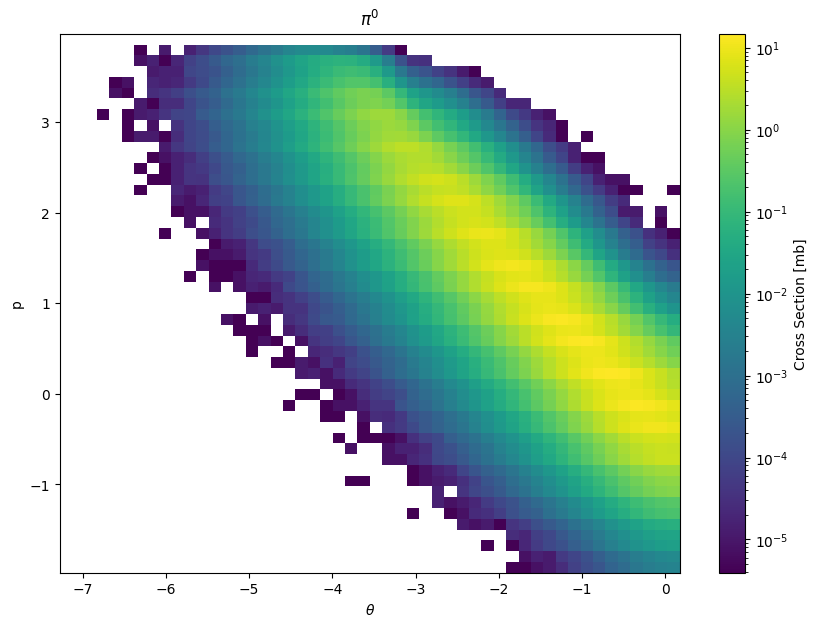

371.9021999999994


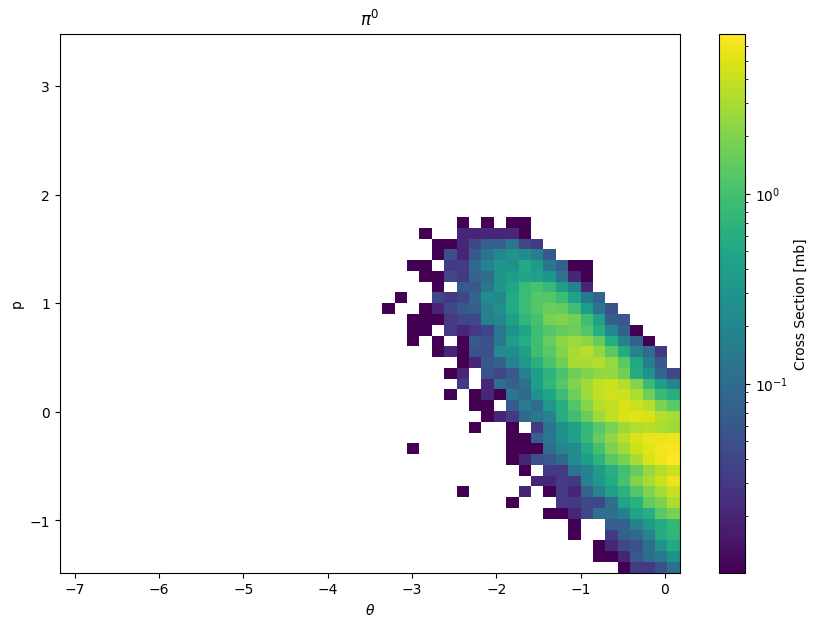

In [12]:
# Sample data
path = "/home/souvik/codes/FORESEE-backup/files/hadrons/13.6TeV/Pythia8/Pythia8_13.6TeV_"
pids = ["111"]
mesons = {"111": r"$\pi^0$", "221": r"$\eta$"}
for pid in pids:
    data = np.genfromtxt(path+pid+".txt")
    print(sum(data[:,-1])/1e9)
    th = data[:,0]   # polar angle
    p = data[:,1]   # momentum
    w = data[:,2] # Weights
    w = [i/1e9 for i in w]

    plt.figure(figsize=(10, 7))

    # weights=w ensures the color represents the sum of weights, not just count
    h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

    plt.colorbar(label='Cross Section [mb]')
    plt.xlabel(r'$\theta$')
    plt.ylabel('p')
    plt.title(mesons[pid])
    plt.savefig("/home/souvik/codes/event generation/EPOSLHC_"+pid)
    plt.show()

# Sample data
path = "/home/souvik/codes/event generation/"
pids = ["pi0"]
mesons = {"pi0": r"$\pi^0$", "eta": r"$\eta$"}
for pid in pids:
    data = np.genfromtxt(path+pid+"_data.dat")
    print(sum(data[:,-1]))
    th = data[:,0]   # polar angle
    p = data[:,1]   # momentum
    w = data[:,2] # Weights

    plt.figure(figsize=(10, 7))

    # weights=w ensures the color represents the sum of weights, not just count
    h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

    plt.colorbar(label='Cross Section [mb]')
    plt.xlabel(r'$\theta$')
    plt.ylabel('p')
    plt.title(mesons[pid])
    plt.savefig("/home/souvik/codes/event generation/pythia_"+pid)
    plt.show()

# # Sample data
# path = "/home/souvik/codes/event generation/"
# pids = ["pi0"]
# mesons = {"pi0": r"$\pi^0$", "eta": r"$\eta$"}
# for pid in pids:
#     data = np.genfromtxt(path+pid+"_data_dune.dat")
#     print(sum(data[:,-1]))
#     th = data[:,0]   # polar angle
#     p = data[:,1]   # momentum
#     w = data[:,2] # Weights

#     plt.figure(figsize=(10, 7))

#     # weights=w ensures the color represents the sum of weights, not just count
#     h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

#     plt.colorbar(label='Cross Section [mb]')
#     plt.xlabel(r'$\theta$')
#     plt.ylabel('p')
#     plt.title(mesons[pid])
#     plt.savefig("/home/souvik/codes/event generation/pythia_"+pid)
#     plt.show()

# # Sample data
# path = "/home/souvik/codes/SHIP_DUNE_FASER/Looking_forward_to_photon_coupled_LLPs-main/files/hadrons/0.12TeV/Pythia/Pythia_0.12TeV_"
# pids = ["111"]
# mesons = {"111": r"$\pi^0$", "221": r"$\eta$"}
# for pid in pids:
#     data = np.genfromtxt(path+pid+".txt")
#     print(sum(data[:,-1]))
#     th = data[:,0]   # polar angle
#     p = data[:,1]   # momentum
#     w = data[:,2] # Weights
#     w = [i for i in w]

#     plt.figure(figsize=(10, 7))

#     # weights=w ensures the color represents the sum of weights, not just count
#     h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

#     plt.colorbar(label='Cross Section [mb]')
#     plt.xlabel(r'$\theta$')
#     plt.ylabel('p')
#     plt.title(mesons[pid])
#     plt.savefig("/home/souvik/codes/event generation/EPOSLHC_"+pid)
#     plt.show()

175.64992137490032


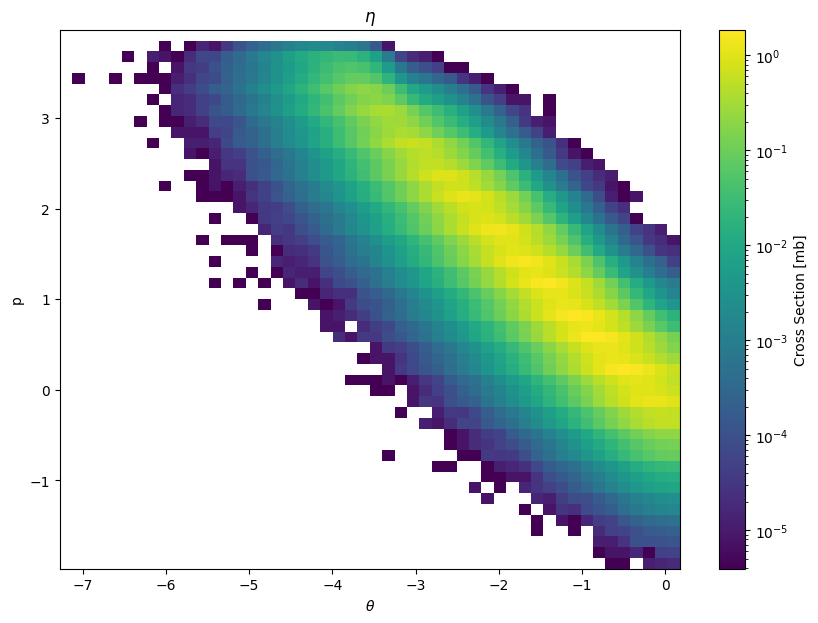

41.67260000000036


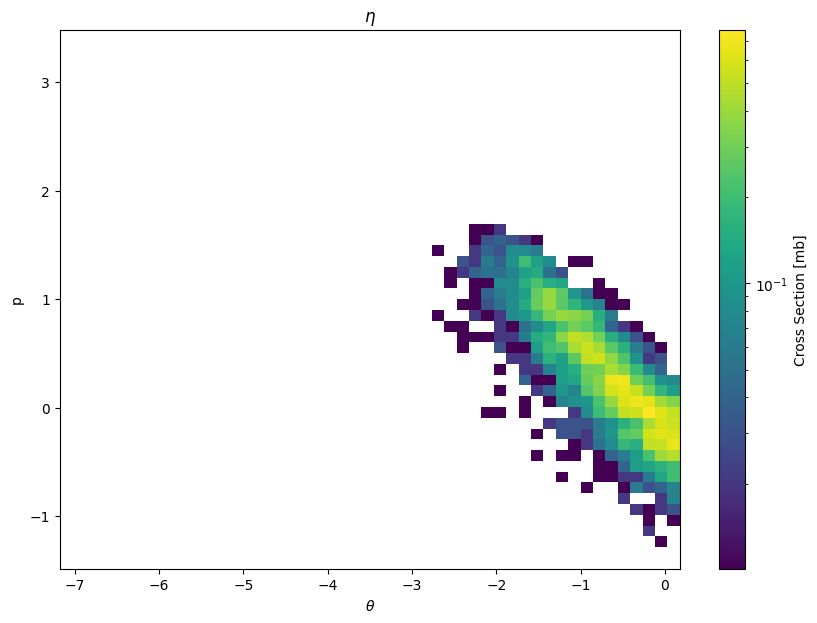

In [13]:
# Sample data
path = "/home/souvik/codes/FORESEE-backup/files/hadrons/13.6TeV/Pythia8/Pythia8_13.6TeV_"
pids = ["221"]
mesons = {"111": r"$\pi^0$", "221": r"$\eta$"}
for pid in pids:
    data = np.genfromtxt(path+pid+".txt")
    print(sum(data[:,-1])/1e9)
    th = data[:,0]   # polar angle
    p = data[:,1]   # momentum
    w = data[:,2] # Weights
    w = [i/1e9 for i in w]

    plt.figure(figsize=(10, 7))

    # weights=w ensures the color represents the sum of weights, not just count
    h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

    plt.colorbar(label='Cross Section [mb]')
    plt.xlabel(r'$\theta$')
    plt.ylabel('p')
    plt.title(mesons[pid])
    plt.savefig("/home/souvik/codes/event generation/EPOSLHC_"+pid)
    plt.show()

# Sample data
path = "/home/souvik/codes/event generation/"
pids = ["eta"]
mesons = {"pi0": r"$\pi^0$", "eta": r"$\eta$"}
for pid in pids:
    data = np.genfromtxt(path+pid+"_data.dat")
    print(sum(data[:,-1]))
    th = data[:,0]   # polar angle
    p = data[:,1]   # momentum
    w = data[:,2] # Weights

    plt.figure(figsize=(10, 7))

    # weights=w ensures the color represents the sum of weights, not just count
    h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

    plt.colorbar(label='Cross Section [mb]')
    plt.xlabel(r'$\theta$')
    plt.ylabel('p')
    plt.title(mesons[pid])
    plt.savefig("/home/souvik/codes/event generation/pythia_"+pid)
    plt.show()

# # Sample data
# path = "/home/souvik/codes/event generation/"
# pids = ["eta"]
# mesons = {"pi0": r"$\pi^0$", "eta": r"$\eta$"}
# for pid in pids:
#     data = np.genfromtxt(path+pid+"_data_dune.dat")
#     print(sum(data[:,-1]))
#     th = data[:,0]   # polar angle
#     p = data[:,1]   # momentum
#     w = data[:,2] # Weights

#     plt.figure(figsize=(10, 7))

#     # weights=w ensures the color represents the sum of weights, not just count
#     h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

#     plt.colorbar(label='Cross Section [mb]')
#     plt.xlabel(r'$\theta$')
#     plt.ylabel('p')
#     plt.title(mesons[pid])
#     plt.savefig("/home/souvik/codes/event generation/pythia_"+pid)
#     plt.show()

# # Sample data
# path = "/home/souvik/codes/SHIP_DUNE_FASER/Looking_forward_to_photon_coupled_LLPs-main/files/hadrons/0.12TeV/Pythia/Pythia_0.12TeV_"
# pids = ["221"]
# mesons = {"111": r"$\pi^0$", "221": r"$\eta$"}
# for pid in pids:
#     data = np.genfromtxt(path+pid+".txt")
#     print(sum(data[:,-1]))
#     th = data[:,0]   # polar angle
#     p = data[:,1]   # momentum
#     w = data[:,2] # Weights
#     w = [i for i in w]

#     plt.figure(figsize=(10, 7))

#     # weights=w ensures the color represents the sum of weights, not just count
#     h = plt.hist2d(th, p, bins=50, weights=w, cmap='viridis', norm=LogNorm())

#     plt.colorbar(label='Cross Section [mb]')
#     plt.xlabel(r'$\theta$')
#     plt.ylabel('p')
#     plt.title(mesons[pid])
#     plt.savefig("/home/souvik/codes/event generation/EPOSLHC_"+pid)
#     plt.show()

--- Extracting from: 14TeV_default2n.npy.txt ---


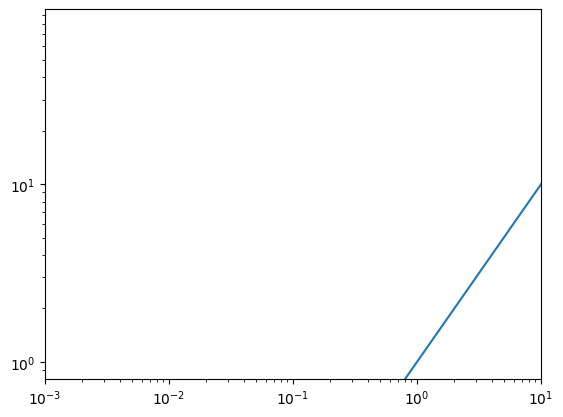

--- Extracting from: 14TeV_alternative12n.npy.txt ---


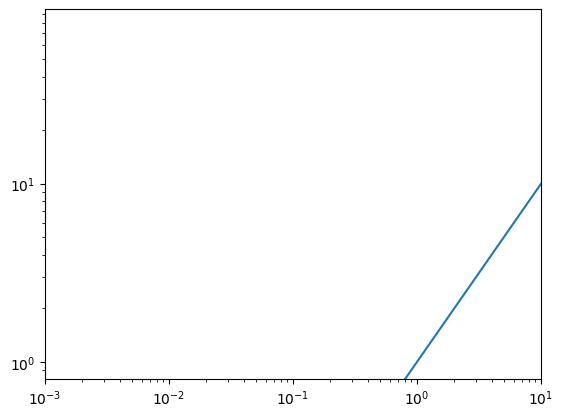

--- Extracting from: 14TeV_default0.npy.txt ---


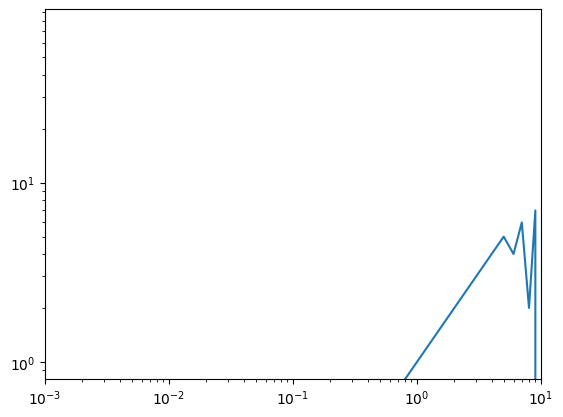

--- Extracting from: 14TeV_default2p.npy.txt ---


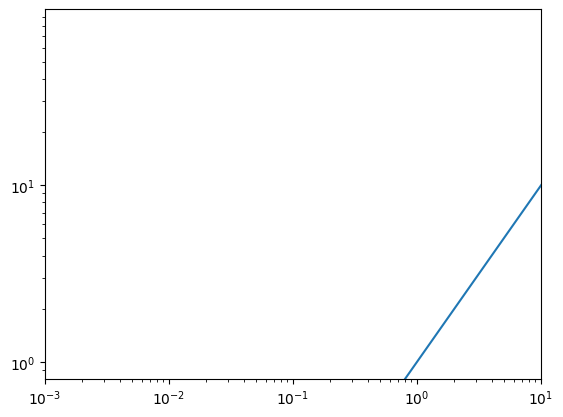

--- Extracting from: 14TeV_alternative2n.npy.txt ---


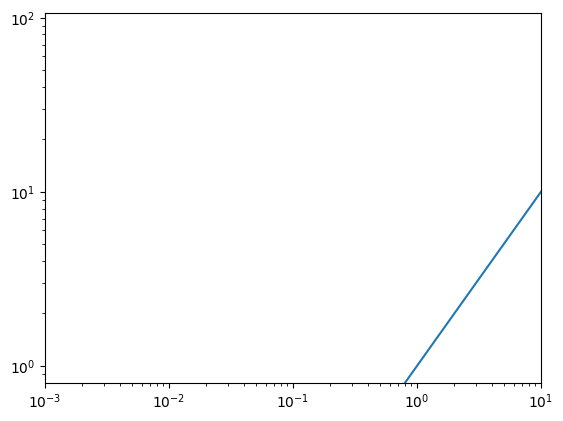

--- Extracting from: 14TeV_alternative0.npy.txt ---


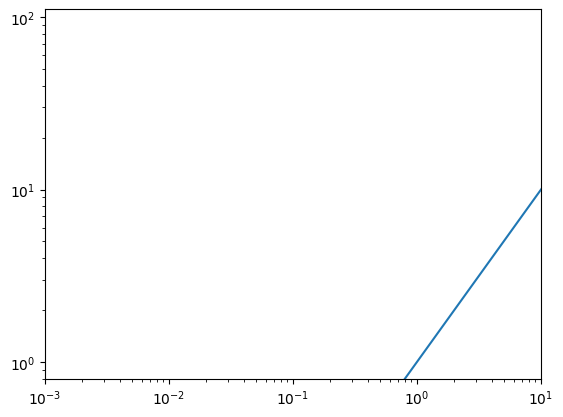

--- Extracting from: 14TeV_alternative2p.npy.txt ---


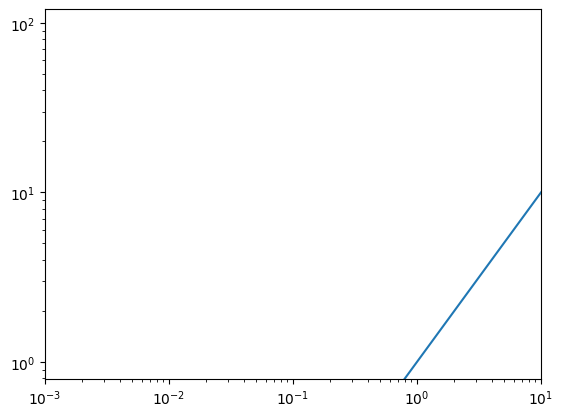

--- Extracting from: 14TeV_default12n.npy.txt ---


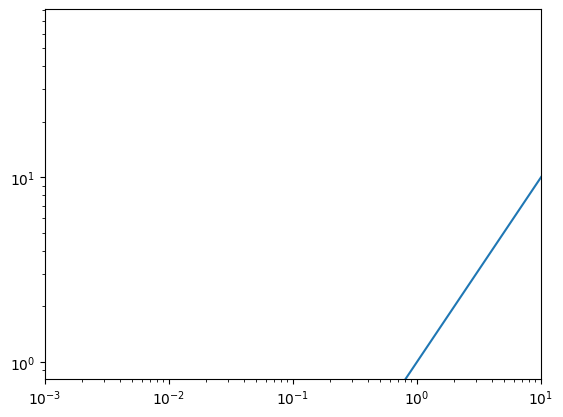

In [22]:
from pathlib import Path

# Define the folder path
folder_path = Path("/home/souvik/Downloads/mixing")

# Loop through all items in the folder
for file_path in folder_path.iterdir():
    # Check if it is a file and has the correct extension
    if file_path.is_file() and file_path.suffix == ".txt":
        print(f"--- Extracting from: {file_path.name} ---")
        
        # Open and read the file content
        with open(file_path, "r", encoding="utf-8") as file:
            mass, mixing = [], []
            for line in file:
                data = line.strip("")
                mass.append(data.split("   ")[0]) 
                mixing.append(data.split("   ")[1])
            plt.plot(mass, mixing)
            plt.loglog()
            plt.xlim(1e-3, 10)
            plt.show()
            